# Checkpoint 2: Same County, Different Weather? Comparing Four Prince George's County Weather Stations
Group Members & Contributions: 

Aashreya: Data Pre-Processing

Dia: Summary Statistics

Natalie, Jenny, Andrew: Paired t-test, correlation test

Luna

## Part 1: Data Pre-processing

### Importing:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 
import numpy as np
import matplotlib.dates as mdates

df = pd.read_csv("dailyweatherdata.csv")
df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,SNOW,SNWD,TMAX,TMIN
0,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-01,0.0,0.0,0.0,57.0,26.0
1,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-02,0.0,0.0,0.0,59.0,26.0
2,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-03,0.0,0.0,0.0,68.0,49.0
3,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-04,0.0,0.0,0.0,70.0,57.0
4,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-05,1.1,0.0,0.0,72.0,38.0


 df.dtypes

### Parse:

In [2]:
# string to date, then pulling out year and month as ints
df["DATE"] = pd.to_datetime(df["DATE"])
df["YEAR"] = df["DATE"].dt.year
df["MONTH"] = df["DATE"].dt.month

#find any impossible rows (ex: low temp higher than the high temp)
bad = df[df["TMIN"] > df["TMAX"]]
print("Rows where TMIN > TMAX:", len(bad))
bad[["NAME", "DATE", "TMAX", "TMIN"]]

Rows where TMIN > TMAX: 5


,NAME,DATE,TMAX,TMIN
6986,"BELTSVILLE, MD US",2002-07-22,22.0,69.0
8386,"BELTSVILLE, MD US",2006-05-22,73.0,74.0
8717,"BELTSVILLE, MD US",2007-04-18,35.0,42.0
9531,"BELTSVILLE, MD US",2009-07-10,10.0,59.0
22679,"LAUREL 3 W, MD US",2000-06-11,71.0,96.0


In [3]:
# Set temperatures to NaN on the days that are impossible
df.loc[df["TMIN"] > df["TMAX"], ["TMAX", "TMIN"]] = float("nan")

#check for duplicate rows (same station on the same day)
print("Duplicate station days:", df.duplicated(["STATION", "DATE"]).sum())

Duplicate station days: 0


### Organize

In [4]:
#simpler column names
df = df.rename(columns={"STATION": "station_id", "NAME": "station", "DATE": "date", "YEAR": "year", 
"MONTH": "month", "TMAX":"tmax", "TMIN":"tmin", "PRCP":"prcp", "SNOW": "snow",
"SNWD": "snow_depth", "LATITUDE": "lat", "LONGITUDE": "lon", "ELEVATION": "elevation"})


#shorter station names
df["station"] = df["station"].replace({"BELTSVILLE, MD US": "Beltsville", "LAUREL 3 W, MD US": "Laurel",
"OXON HILL, MD US": "Oxon Hill", "UPPER MARLBORO 3 NNW, MD US": "Upper Marlboro"})

#sort so each station's days are in order 
df = df.sort_values(["station","date"]).reset_index(drop=True)

# Mark each day as rainy (1) or dry (0) so we can try to predict if it'll rain
df["rain_day"] = (df["prcp"] > 0).astype(int)

# If rain wasn't recorded, we don't know, so leave it blank instead of calling it dry
df.loc[df["prcp"].isna(), "rain_day"] = float("nan")

# Add yesterday's low, since it's a good clue for predicting today's low
df["tmin_yesterday"] = df.groupby("station")["tmin"].shift(1)

df.head()

,station_id,station,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday
0,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-01,0.00,0.0,0.0,55.0,27.0,2000,1,0.0,NaN
1,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-02,0.00,0.0,0.0,52.0,27.0,2000,1,0.0,27.0
2,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-03,0.00,0.0,0.0,67.0,48.0,2000,1,0.0,27.0
3,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-04,0.00,0.0,0.0,67.0,57.0,2000,1,0.0,48.0
4,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-05,1.22,0.0,0.0,69.0,36.0,2000,1,1.0,57.0


### Exploratory Data Analysis

In [5]:
print("Number of entries:", df.shape[0])
print("Number of features:", df.shape[1])
print(df["station"].value_counts())

Number of entries: 28270
Number of features: 15
station
Beltsville        9482
Oxon Hill         6982
Upper Marlboro    6053
Laurel            5753
Name: count, dtype: int64


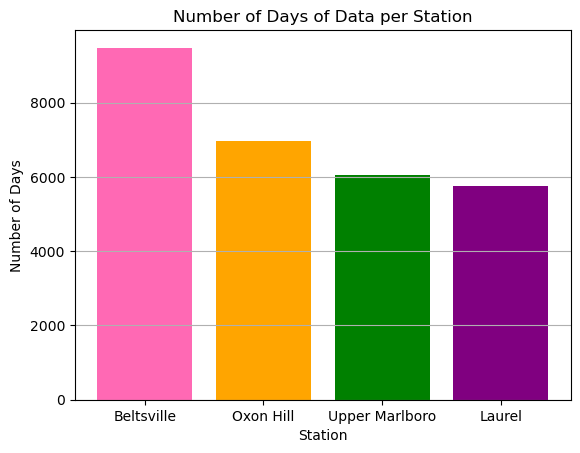

In [6]:
counts = df["station"].value_counts()
plt.figure
plt.bar(counts.index, counts.values, color=['hotpink', 'orange', 'green','purple'])
plt.title("Number of Days of Data per Station")
plt.xlabel("Station")
plt.ylabel("Number of Days")
plt.grid(axis="y")
plt.show()

In [7]:
# checking which years does each station has data for
pd.crosstab(df["year"], df["station"])

station,Beltsville,Laurel,Oxon Hill,Upper Marlboro
year,,,,
2000,366,366,0,366
2001,365,365,0,365
2002,365,365,213,365
2003,365,365,360,365
2004,366,366,362,366
2005,365,365,363,365
2006,365,335,365,335
2007,365,365,365,365
2008,366,366,366,366


In [8]:
# Fraction of missing values for each station
df.groupby("station")[["tmax", "tmin", "prcp", "snow", "snow_depth"]].apply(lambda g: g.isna().mean()).round(3)

,tmax,tmin,prcp,snow,snow_depth
station,,,,,
Beltsville,0.000,0.001,0.000,0.000,0.000
Laurel,0.242,0.243,0.066,0.257,0.303
Oxon Hill,0.012,0.011,0.004,0.008,0.019
Upper Marlboro,0.020,0.020,0.021,0.250,0.255


This dataset has 28,270 entries. Beltsville is overrepresented in the sample since it's the only station with data for all of the years. The other stations stopped reporting halfway through. Laurel is also missing about 24% of it's temperatures and Laurel and Upper Marlboro are missing about a quarter of their snow-depth values. Due to the stations not all having all of the years when we compare two stations we need to only sue dates both of them have. 

## Part 2: Summary Statistics

To break down our dataset's main attributes, the data in this dataframe records climate data including rain, snow, general precipitation, and temperature throughout 2 decades at four different stations in Maryland (Beltsville, Oxon Hill, Upper Marlboro, Laurel). Let's take a general look at this dataset to see what we'll focus on doing some summary stats for. 

In [9]:
#doing a brief preliminary pass
df.describe()

,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday
count,28270.000000,28270.000000,28270.000000,28270,27730.000000,25216.000000,24848.000000,26670.000000,26665.000000,28270.000000,28270.000000,27730.000000,26663.000000
mean,38.945149,-76.905823,62.410743,2010-09-25 14:33:07.067562752,0.126494,0.046923,0.164078,66.445632,46.880818,2010.238168,6.477184,0.325424,46.880996
min,38.795500,-76.994810,39.600000,2000-01-01 00:00:00,0.000000,0.000000,0.000000,14.000000,-4.000000,2000.000000,1.000000,0.000000,-4.000000
25%,38.851900,-76.931500,44.200000,2005-06-13 00:00:00,0.000000,0.000000,0.000000,52.000000,32.000000,2005.000000,4.000000,0.000000,32.000000
50%,39.030200,-76.931500,44.200000,2010-04-30 00:00:00,0.000000,0.000000,0.000000,68.000000,47.000000,2010.000000,6.000000,0.000000,47.000000
75%,39.030200,-76.900200,57.900000,2015-03-22 00:00:00,0.050000,0.000000,0.000000,82.000000,62.000000,2015.000000,9.000000,1.000000,62.000000
max,39.084700,-76.768300,121.900000,2025-12-31 00:00:00,7.460000,24.000000,28.000000,105.000000,83.000000,2025.000000,12.000000,1.000000,83.000000
std,0.117399,0.078949,30.787792,NaN,0.359662,0.523295,1.210890,18.266841,17.146657,6.384453,3.434827,0.468541,17.146456


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28270 entries, 0 to 28269
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   station_id      28270 non-null  object        
 1   station         28270 non-null  object        
 2   lat             28270 non-null  float64       
 3   lon             28270 non-null  float64       
 4   elevation       28270 non-null  float64       
 5   date            28270 non-null  datetime64[ns]
 6   prcp            27730 non-null  float64       
 7   snow            25216 non-null  float64       
 8   snow_depth      24848 non-null  float64       
 9   tmax            26670 non-null  float64       
 10  tmin            26665 non-null  float64       
 11  year            28270 non-null  int32         
 12  month           28270 non-null  int32         
 13  rain_day        27730 non-null  float64       
 14  tmin_yesterday  26663 non-null  float64       
dtypes:

It seems like the main attributes of this dataset are temperature, precipitation, and snow, so let's take a better look at those. Elevation and location data relating to each of the four stations might be relevant at somepoint, but given that there's only 4 unique rows of data amongst those columns (since the stations don't move), it's not as pertinent as the actual climate data. The tmin_yesterday and rain columns we made will come in handy for the ML part of the tutorial we'll handle later, so let's just focus on the main 3 attributes I mentioned above. It's also worth nothing that Beltsville has so much more data than any of the other stations, but each station has several thousand records, so that should be good for our purposes. It is something to take into account in the future when doing analysis over specific periods of time for which Beltsville has data but the other stations don't. 

First, let's look into temperature data. We only have the maximum and minimum temperatures recorded per each day, so to get something useful we can look at the daily temperature ranges. 

In [11]:
df['temperature_range'] = df['tmax'] - df['tmin']

#Now that I have the last column I'll make for this section, I want to know how many not null entries there are for each station in each column so I can accurately make claims on the outlier ratios later on
df.groupby('station').count()

,station_id,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday,temperature_range
station,,,,,,,,,,,,,,,
Beltsville,9482,9482,9482,9482,9482,9478,9479,9479,9478,9475,9482,9482,9478,9474,9475
Laurel,5753,5753,5753,5753,5753,5373,4273,4011,4361,4357,5753,5753,5373,4357,4357
Oxon Hill,6982,6982,6982,6982,6982,6956,6923,6846,6900,6903,6982,6982,6956,6902,6886
Upper Marlboro,6053,6053,6053,6053,6053,5923,4541,4512,5931,5930,6053,6053,5923,5930,5930


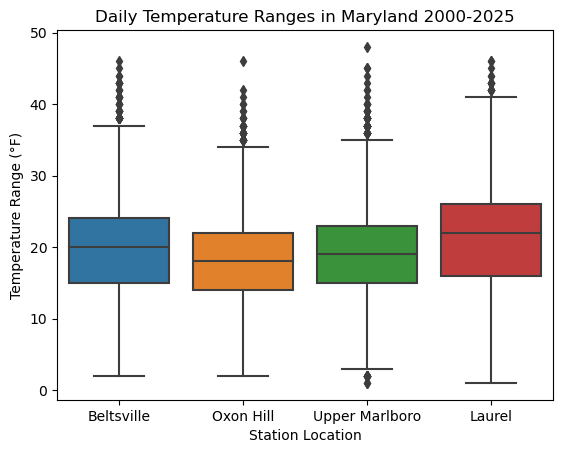

In [12]:
plt.figure()
ax = sns.boxplot(data = df, x = 'station', y = 'temperature_range')
labels = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel']
ax.set_xticks(ticks = range(len(labels)), labels = labels)
plt.title('Daily Temperature Ranges in Maryland 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Temperature Range (°F)')
plt.show()

From the boxlpot, it seems that most of the temperature ranges are visibly around the 15-25 degrees Fahrenheit per day. Outliers for temperature range are typically around the 35-50 degrees Fahrenheit range. I'm interested to see these outliers and their dates, so I'll display them below, and how many there are:

In [13]:
#printing outliers
Q1 = df['temperature_range'].quantile(0.25)
Q3  = df['temperature_range'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierstemprange = df.loc[(df['temperature_range'] < lower) | (df['temperature_range'] > upper), ['station', 'temperature_range', 'date']]
outlierstemprange.groupby('station').head()

,station,temperature_range,date
13,Beltsville,39.0,2000-01-14
16,Beltsville,43.0,2000-01-17
97,Beltsville,40.0,2000-04-07
99,Beltsville,44.0,2000-04-09
302,Beltsville,38.0,2000-10-29
9526,Laurel,38.0,2000-02-14
9549,Laurel,39.0,2000-03-08
9578,Laurel,38.0,2000-04-06
10269,Laurel,40.0,2002-02-26
10621,Laurel,42.0,2003-02-13


In [14]:
#printing outlier sums
print("There are", outlierstemprange['temperature_range'].count(), "many outliers for daily temperature range in this dataset across all stations.")

There are 166 many outliers for daily temperature range in this dataset across all stations.


Not too many outliers it seems. Even for the station that only has around 4000 entries for temperature range (Laurel), if we assumed all the outliers belonged to that station (which we know is not true from the outlier dataframe printed above), that would still be less than 5% of the data. 

Now we'll look into individual temperature range distirbutions per station to get a better look at temperature data for each region, and also because not every station has data for the full 25 years. 

<Figure size 640x480 with 0 Axes>

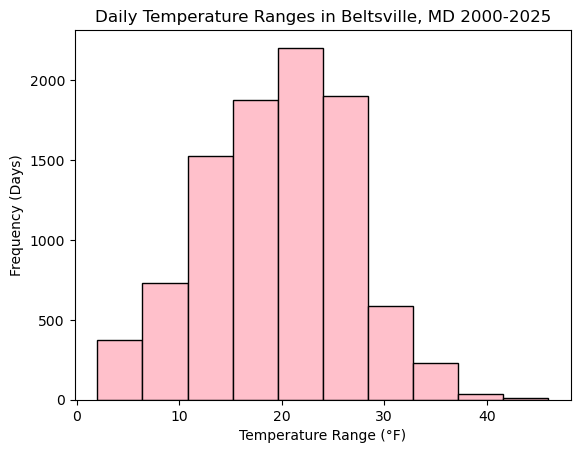

<Figure size 640x480 with 0 Axes>

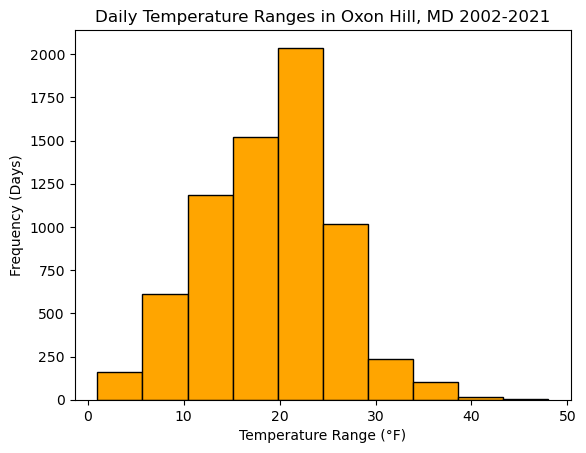

<Figure size 640x480 with 0 Axes>

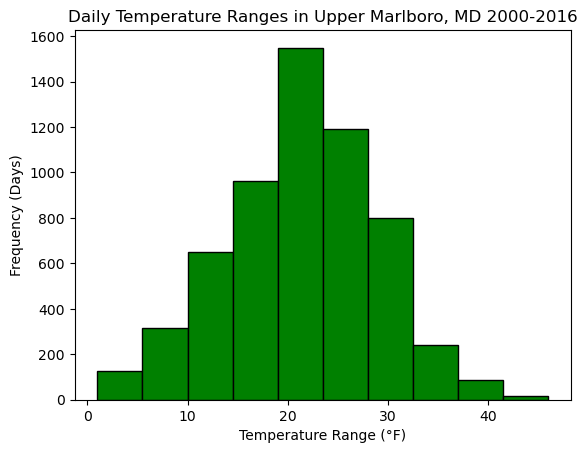

<Figure size 640x480 with 0 Axes>

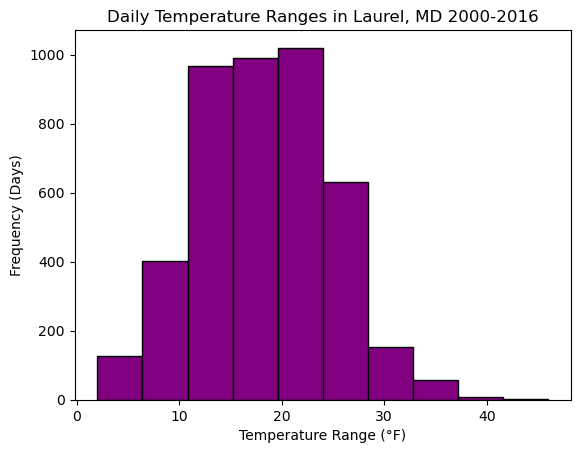

In [15]:
#individual histogram distributions of temperature ranges
stationstemprange = df.groupby('station')[['temperature_range']]

beltsvilletemprange = stationstemprange.get_group('Beltsville')
oxonhilltemprange = stationstemprange.get_group('Oxon Hill')
uppermarlborotemprange = stationstemprange.get_group('Upper Marlboro')
laureltemprange = stationstemprange.get_group('Laurel')


plt.figure()
beltsvilletemprange.hist(grid=False, edgecolor='black', color='pink')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Beltsville, MD 2000-2025')
plt.show()

plt.figure()
oxonhilltemprange.hist(grid=False, edgecolor='black', color='orange')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Oxon Hill, MD 2002-2021')
plt.show()

plt.figure()
uppermarlborotemprange.hist(grid=False, edgecolor='black', color='green')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Upper Marlboro, MD 2000-2016')
plt.show()

plt.figure()
laureltemprange.hist(grid=False, edgecolor='black', color='purple')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Laurel, MD 2000-2016')
plt.show()

Now we'll look into precipitation data, and do similar analysis first with group boxplots and then individual histograms for each station. 

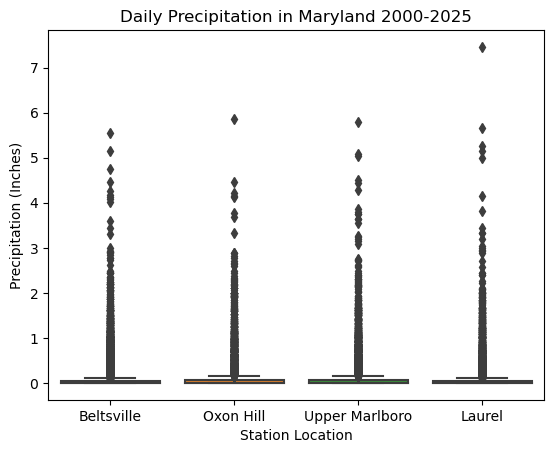

In [16]:
plt.figure()
ax = sns.boxplot(data = df, x = 'station', y = 'prcp')
plt.title('Daily Precipitation in Maryland 2000-2025')
plt.xlabel('Station Location')
labels = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel']
ax.set_xticks(ticks = range(len(labels)), labels = labels)
plt.ylabel('Precipitation (Inches)')
plt.show()

In [17]:
#printing outliers
Q1 = df['prcp'].quantile(0.25)
Q3  = df['prcp'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df.loc[(df['prcp'] < lower) | (df['prcp'] > upper), ['station', 'prcp', 'date']]
outliers.groupby('station').head()

,station,prcp,date
4,Beltsville,1.22,2000-01-05
10,Beltsville,0.75,2000-01-11
19,Beltsville,0.18,2000-01-20
23,Beltsville,0.30,2000-01-24
24,Beltsville,0.53,2000-01-25
9485,Laurel,1.12,2000-01-04
9491,Laurel,0.78,2000-01-10
9501,Laurel,0.41,2000-01-20
9506,Laurel,0.71,2000-01-25
9511,Laurel,0.27,2000-01-30


In [18]:
#printing outlier sums
print("There are", outliers['prcp'].count(), "many outliers for daily precipitation in this dataset across all stations.")

There are 5335 many outliers for daily precipitation in this dataset across all stations.


Okay, so there's quite a bit of outliers for precipitation, but this seems to be because there's just so much data for which daily precipitation is less than an inch/is 0 inches. This is kind of surprising to me, especially because I'd expect rainy seasons to have a lot more rain, which is probably why there are around 20% outliers over the whole dataset (from the count of this df we did earlier, 9,400+5,000+5,000+6,000 is around 27,400, a general estimate of how many not null values there are for precipitation data, and 5,335/27,400 is around 20%, very rough math but the important thing is that 5,335 is a big amount of outliers regardless). It is interesting that the IQR is so small, though, but it's probably because Maryland has been going through a drought for quite a long time. Perhaps this is something to look further into for our tutorial! I do want to see, though, if any particular station is the reason for the lack of rain, so let's make some histograms. 

<Figure size 640x480 with 0 Axes>

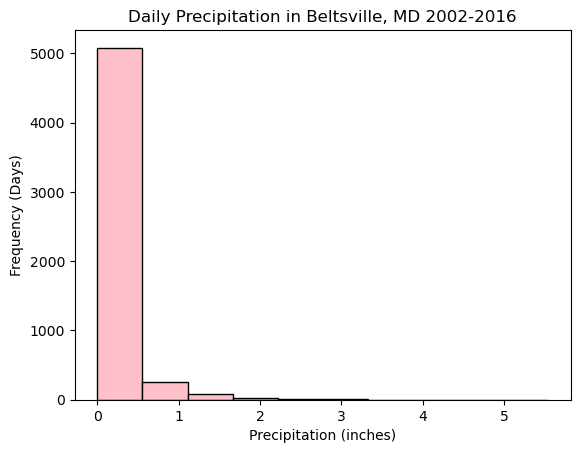

<Figure size 640x480 with 0 Axes>

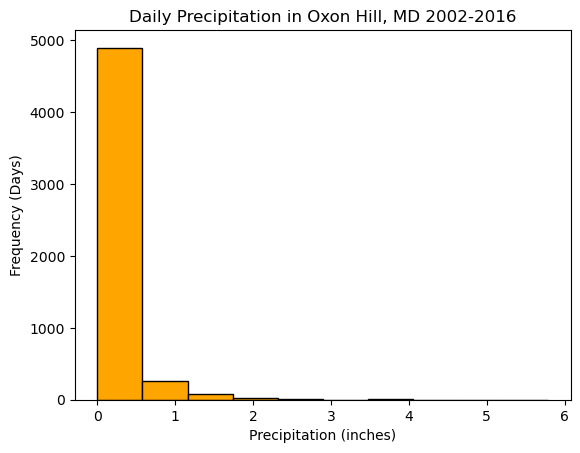

<Figure size 640x480 with 0 Axes>

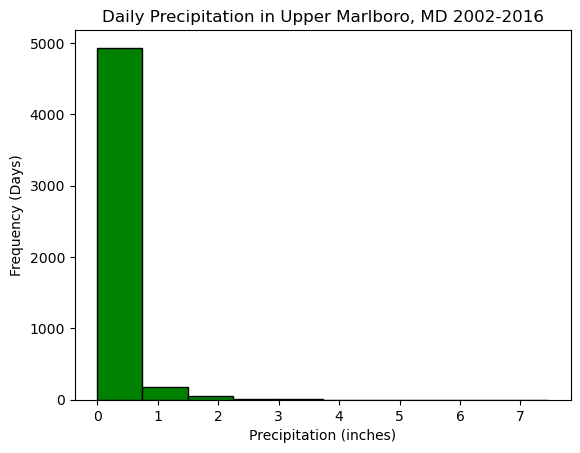

<Figure size 640x480 with 0 Axes>

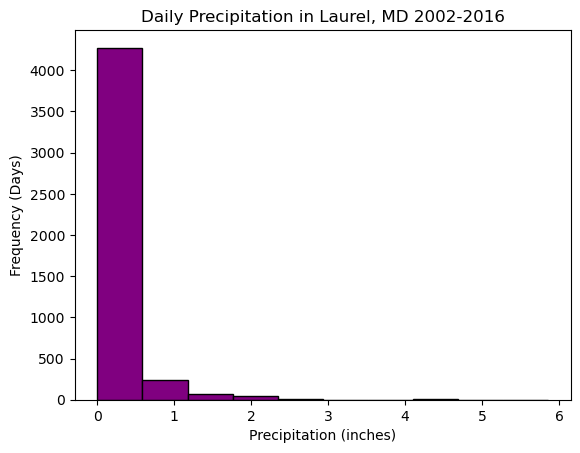

In [19]:
#Grouped histograms per station
#to get rid of the extra data Beltsville has we'll just filter down to the range they all generally have data for, which is 2002-2016, as we saw in the EDA section above

newdf = df[(df['year'] >= 2002) & (df['year'] <= 2016)]

#average temperature range
stationsprcp = newdf.groupby('station')[['prcp']]

beltsvilleprcp = stationsprcp.get_group('Beltsville')
oxonhillprcp = stationsprcp.get_group('Oxon Hill')
uppermarlboroprcp = stationsprcp.get_group('Upper Marlboro')
laurelprcp = stationsprcp.get_group('Laurel')

plt.figure()
beltsvilleprcp.hist(grid=False, edgecolor='black', color='pink')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Beltsville, MD 2002-2016')
plt.show()

plt.figure()
oxonhillprcp.hist(grid=False, edgecolor='black', color='orange')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Oxon Hill, MD 2002-2016')
plt.show()

plt.figure()
uppermarlboroprcp.hist(grid=False, edgecolor='black', color='green')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Upper Marlboro, MD 2002-2016')
plt.show()

plt.figure()
laurelprcp.hist(grid=False, edgecolor='black', color='purple')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Laurel, MD 2002-2016')
plt.show()


Looking at these histograms, it doesn't seem like any one particular station is responsible for the significant records of 0 rain, especially given that theis is data over the same timeframe. When I looked at this data for each station's natural time frames, Beltsville had the most amount of days with 0 rain, but since that could be attributed to the fact that Beltsillve simply has the most data (in fact, thousands of records more than the other stations), I just got rid of those records and created a uniform time window to look at all 4 stations. It seems like, then, Maryland just does not get a lot of rain, or at least not around these stations/these stations don't record it. This'll be interesting to look into during the tutorial portion of this project. One direction we might take is looking specifically into time series to get time periods in which there is heavy precipitation, if there are any.  

Looking into Snow Depth

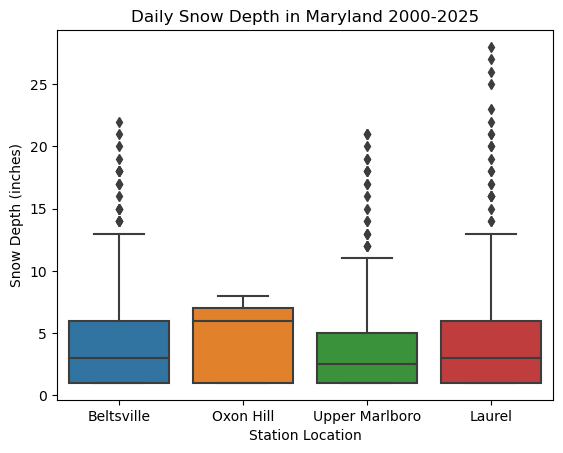

In [20]:
plt.figure()

#there's a lot of 0's in the snow depth, which we delete this time because they probably come from months when it doesn't usually snow, which isn't super helpful. We want to know about snow data when we actually get snow
helpful_snow_depth = df[df['snow_depth'] > 0].dropna(subset=['snow_depth'])
ax = sns.boxplot(data = helpful_snow_depth, x = 'station', y = 'snow_depth')
labels = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel']
ax.set_xticks(ticks = range(len(labels)), labels = labels)
plt.title('Daily Snow Depth in Maryland 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Snow Depth (inches)')
plt.show()

Displaying outliers and how many there are:

In [21]:
Q1 = helpful_snow_depth['snow_depth'].quantile(0.25)
Q3  = helpful_snow_depth['snow_depth'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierssnowdepth = helpful_snow_depth.loc[(helpful_snow_depth['snow_depth'] < lower) | (helpful_snow_depth['snow_depth'] > upper), ['station', 'snow_depth', 'date']]
outlierssnowdepth.groupby('station').head()

,station,snow_depth,date
1143,Beltsville,18.0,2003-02-17
1144,Beltsville,19.0,2003-02-18
1145,Beltsville,17.0,2003-02-19
1146,Beltsville,15.0,2003-02-20
1147,Beltsville,15.0,2003-02-21
15495,Oxon Hill,13.0,2003-02-17
15496,Oxon Hill,13.0,2003-02-18
15497,Oxon Hill,12.0,2003-02-19
16575,Oxon Hill,13.0,2006-02-12
17982,Oxon Hill,17.0,2009-12-20


In [22]:
#printing outlier count
print("There are", outlierssnowdepth['snow_depth'].count(), "many outliers for snow depth in this dataset across all stations.")

There are 79 many outliers for snow depth in this dataset across all stations.


For the amount of data we have for each station (thousands), there aren't many outliers (79 is less than 2% of the data records since as we saw earlier, these columns have at least 4,000 non-null entries). That being said, the outliers we have seem significant. Laurel, in particular, had almost 30 feet of snow on the ground at some point! This outlier probably shouldn't be removed in analysis, but kept with a special note (like this one). For analysis one direction we might take (just like with precipitation) is looking specifically into time series to get time periods in which there is heavy snowfall. We'd probably expect to get the winter months, but it'll make for a good exercise in a tutorial since we'll be looking at several months and several years in different locations, and there's many different ways to analyze such data. 

Did a histogram for each station for snow depth, but it didn't really add anything more than what the boxplot already showed us. Looking into each individual station was mostly just helpful for temperature ranges.

Now we move on to general snowfall data. 

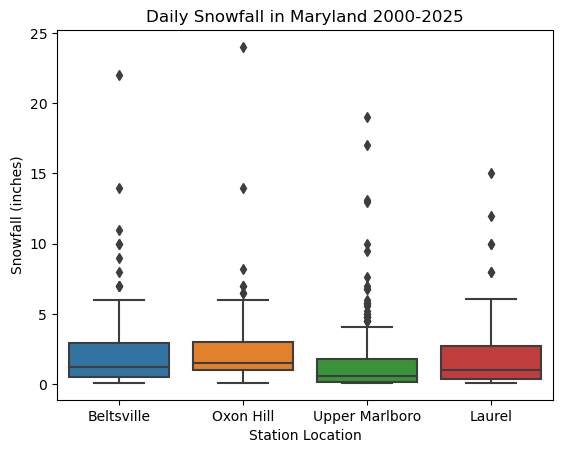

In [23]:
plt.figure()
#again, looking at snow data when it actually happens
helpful_snow = df[df['snow'] > 0].dropna(subset=['snow'])
ax = sns.boxplot(data = helpful_snow, x = 'station', y = 'snow')
labels = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel']
ax.set_xticks(ticks = range(len(labels)), labels = labels)
plt.title('Daily Snowfall in Maryland 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Snowfall (inches)')
plt.show()

Displaying outliers and how many there are:

In [24]:
Q1 = helpful_snow['snow'].quantile(0.25)
Q3  = helpful_snow['snow'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierssnow = helpful_snow.loc[(helpful_snow['snow'] < lower) | (helpful_snow_depth['snow'] > upper), ['station', 'snow', 'date']]

outlierssnow.groupby('station').head()

,station,snow,date
24,Beltsville,6.0,2000-01-25
1133,Beltsville,7.0,2003-02-07
1142,Beltsville,7.0,2003-02-16
1143,Beltsville,11.0,2003-02-17
1486,Beltsville,6.0,2004-01-26
10551,Laurel,6.0,2002-12-05
15485,Oxon Hill,6.8,2003-02-07
15494,Oxon Hill,6.0,2003-02-16
15495,Oxon Hill,9.5,2003-02-17
16225,Oxon Hill,5.7,2005-02-25


In [25]:
#printing outlier count
print("There are", outlierssnow['snow'].count(), "many outliers for snow depth in this dataset across all stations.")

There are 46 many outliers for snow depth in this dataset across all stations.


It seems there's not too many outliers in the snowfall data, although Upper Marlboro visibly has the most. 46 outliers over the whole data set is still not that many considering there's thousands of datapoints being recorded. Otherwise, the data seems to generally have a good range, especially given that, again, we're talking about thousands of rows of data for each region. Most snowfall seems to fall within the 0 to 5 inch range, particularly on the lower end of that range, which makes sense for Maryland. Interestingly enough, snowfall doesn't really relate to snow depth, and its general range is way smaller than snow depth, which one could argue might come from snow depth accumulating over multiple days of recorded snowfall. It'll be interesting to maybe look at time series between snow depth and snow fall and see if we can draw some evidence from that data. 

## Part 3: Correlation

In [26]:
df.corr(numeric_only=True)

,lat,lon,elevation,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday,temperature_range
lat,1.000000,-0.003198,0.495827,-0.005171,-0.012951,-0.040745,-0.021833,0.001590,-0.016360,-0.005480,-0.014770,0.001674,-0.060776
lon,-0.003198,1.000000,-0.143024,-0.007181,0.010298,0.036088,-0.012549,-0.056384,-0.239783,-0.009124,-0.028470,-0.056362,0.106558
elevation,0.495827,-0.143024,1.000000,0.012552,-0.012702,-0.060173,-0.000099,0.042296,-0.186759,-0.010756,0.004086,0.042275,-0.104384
prcp,-0.005171,-0.007181,0.012552,1.000000,0.121034,0.036167,0.018486,0.102445,-0.000182,0.025042,0.506377,0.102214,-0.203019
snow,-0.012951,0.010298,-0.012702,0.121034,1.000000,0.503329,-0.168805,-0.139581,-0.003984,-0.085586,0.128944,-0.129683,-0.099061
snow_depth,-0.040745,0.036088,-0.060173,0.036167,0.503329,1.000000,-0.236667,-0.219190,-0.014336,-0.138917,0.038408,-0.217503,-0.079880
tmax,-0.021833,-0.012549,-0.000099,0.018486,-0.168805,-0.236667,1.000000,0.924192,0.009145,0.228838,-0.014502,0.882278,0.346494
tmin,0.001590,-0.056384,0.042296,0.102445,-0.139581,-0.219190,0.924192,1.000000,0.020317,0.251359,0.104244,0.933083,-0.038043
year,-0.016360,-0.239783,-0.186759,-0.000182,-0.003984,-0.014336,0.009145,0.020317,1.000000,-0.024035,0.021756,0.019944,-0.025861
month,-0.005480,-0.009124,-0.010756,0.025042,-0.085586,-0.138917,0.228838,0.251359,-0.024035,1.000000,-0.034718,0.261015,-0.019037


The Pearson correlation matrix shows several strong relationships between weather variables. The strongest positive correlations are between minimum temperature (tmin) and yesterday's minimum temperature (tmin_yesterday, r = 0.933), as well as maximum and minimum temperatures (r = 0.924). Snowfall and snow depth also have a moderate positive correlation (r = 0.503), while precipitation and rainy days are moderately correlated (r = 0.506). Temperature range has weak negative correlations with precipitation (r = -0.203) and rainy days (r = -0.294). Overall, temperature-related variables have the strongest correlations, while most geographical and temporal variables show relatively weak linear relationships with other features.

## Part 4: Hypothesis Test

Hypothesis test: Is Beltsville warmer than Oxon Hill?

We use a paired t-test because both stations record temperature on the same days, so each shared date is one matched pair. We merge on date so only days both stations have are compared.

Null Hypothesis:The mean difference in daily temperature (Beltsville − Oxon Hill) is 0.
Alternative Hypothesis: The mean difference is not 0.
Significance level: α = 0.05

In [27]:
# daily mean temperature
df["tmean"] = (df["tmax"] + df["tmin"]) / 2

beltsville = df[df["station"] == "Beltsville"][["date", "tmean"]]
oxon = df[df["station"] == "Oxon Hill"][["date", "tmean"]]

# keep only dates both stations have + drop missing values
paired = beltsville.merge(oxon, on="date", suffixes=("_belts", "_oxon")).dropna()

print("Paired days:", len(paired))
print("Beltsville mean:", round(paired["tmean_belts"].mean(), 2))
print("Oxon Hill mean:", round(paired["tmean_oxon"].mean(), 2))

# paired t-test
t_stat, p_val = stats.ttest_rel(paired["tmean_belts"], paired["tmean_oxon"])
print("t =", round(t_stat, 3), " p =", p_val)

Paired days: 6867
Beltsville mean: 56.25
Oxon Hill mean: 57.66
t = -64.112  p = 0.0


Result: We compared daily mean temperatures on 6,867 days that both stations had data. Beltsville averaged 56.25 °F and Oxon Hill averaged 57.66 °F, a difference of about 1.4 °F. The paired t-test gave t = -64.11 and p < 0.001.

Conclusion: Since p is less than 0.05, we reject the null hypothesis. There is strong evidence that Beltsville and Oxon Hill have different average daily temperatures, with Oxon Hill running about 1.4 °F warmer. One possible explanation is that Oxon Hill is more urban and closer to Washington, DC, but this test only shows that a difference exists, not why.

Caveat: Daily temperatures are correlated from one day to the next, so the effective sample size is smaller than 6,867 and the t-statistic is likely overstated. The difference is large enough relative to the day-to-day variation that the conclusion would almost certainly still hold.